# MIT Academy of Engineering, Alandi, Pune

## Department of Computer Engineering
### B.Tech Semester V (2026–2027)

**Subject:** Artificial Intelligence and Machine Learning (AIML)

**Lab Assignment No.:** 4

**Title:** Classification Model Training

| Particular | Details |
|---|---|
| Name | Akhilesh Kombe |
| Division | A |
| Batch | A3 |
| Roll No. | 57 |
| PRN | 202401040244 |

## 1. Aim

To develop and train classification models using Support Vector Machine (SVM) and K-Nearest Neighbors (KNN), evaluate their performance using accuracy, precision, recall, F1-score and log loss, and compare their suitability for classification tasks.

## 2. Objectives

1. Understand the working principles of SVM and KNN classification algorithms.
2. Load and preprocess a real-world dataset.
3. Split the dataset into training and testing sets.
4. Train SVM and KNN classification models.
5. Evaluate the models using accuracy, precision, recall, F1-score and log loss.
6. Visualize confusion matrices and compare model performance.
7. Analyze the suitability of both algorithms for the selected classification task.

## 3. Software Requirements

- Google Colab
- Python 3
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn

## 4. Theory

**Classification:** Classification is a supervised machine learning technique used to predict discrete class labels based on input features.

**Support Vector Machine (SVM):** SVM identifies a decision boundary that maximizes the margin between classes. The RBF kernel enables nonlinear classification.

**K-Nearest Neighbors (KNN):** KNN predicts the class of a new observation by finding its K nearest training observations and applying majority voting.

**Accuracy:** Proportion of correctly classified samples.

**Precision:** Proportion of predicted positive samples that are actually positive.

**Recall:** Proportion of actual positive samples correctly identified.

**F1-score:** Harmonic mean of precision and recall.

**Log Loss:** Measures the quality of predicted class probabilities. Lower log loss indicates better probabilistic predictions.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

df = pd.read_csv("/content/online_shoppers_intention.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  T

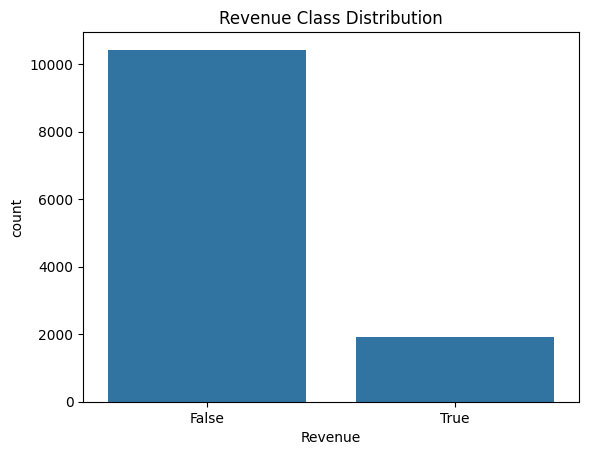

In [3]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Revenue"].value_counts())

sns.countplot(data=df, x="Revenue")
plt.title("Revenue Class Distribution")
plt.show()


In [4]:

X = df.drop("Revenue", axis=1)
y = df["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.columns.difference(numeric_cols).tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_cols)
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 9864
Testing samples: 2466


## 5. SVM Model Training

In [5]:

svm_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)

print("SVM model trained successfully!")
print(classification_report(y_test, svm_pred, zero_division=0))


SVM model trained successfully!
              precision    recall  f1-score   support

           0       0.91      0.96      0.94      2084
           1       0.71      0.46      0.56       382

    accuracy                           0.89      2466
   macro avg       0.81      0.71      0.75      2466
weighted avg       0.88      0.89      0.88      2466



## 6. KNN Model Training

In [6]:

knn_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean"
    ))
])

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)
knn_prob = knn_model.predict_proba(X_test)

print("KNN model trained successfully!")
print(classification_report(y_test, knn_pred, zero_division=0))


KNN model trained successfully!
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      2084
           1       0.65      0.40      0.49       382

    accuracy                           0.87      2466
   macro avg       0.77      0.68      0.71      2466
weighted avg       0.86      0.87      0.86      2466



In [7]:

def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Log Loss": log_loss(y_true, y_prob)
    }

results = pd.DataFrame([
    evaluate_model("SVM", y_test, svm_pred, svm_prob),
    evaluate_model("KNN", y_test, knn_pred, knn_prob)
])

print("CLASSIFICATION MODEL COMPARISON")
display(results.round(4))


CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,Log Loss
0,SVM,0.8869,0.7068,0.4607,0.5578,0.2968
1,KNN,0.8731,0.6456,0.4005,0.4943,1.7046


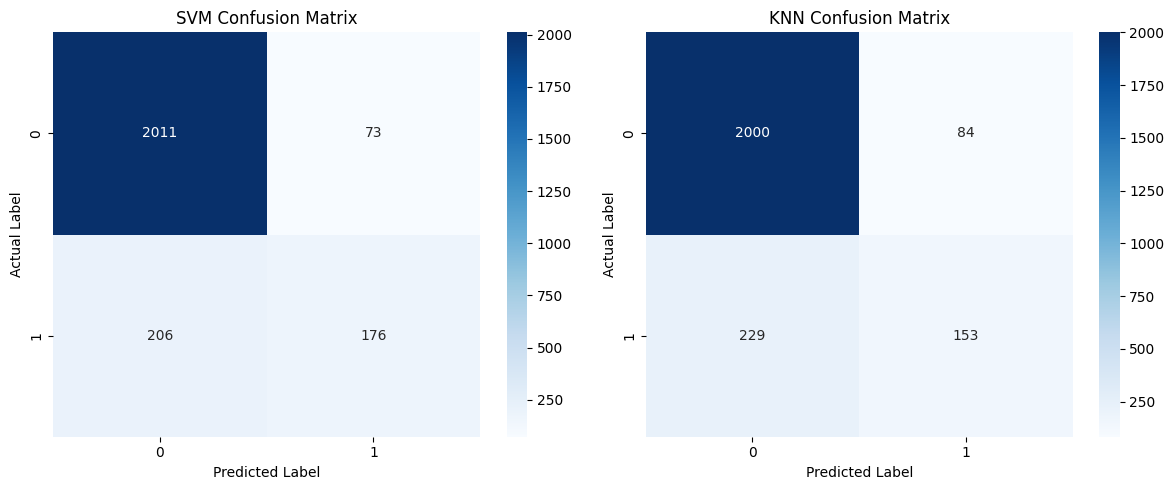

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name, predictions in [
    (axes[0], "SVM", svm_pred),
    (axes[1], "KNN", knn_pred)
]:
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm, annot=True, fmt="d",
        cmap="Blues", ax=ax
    )
    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


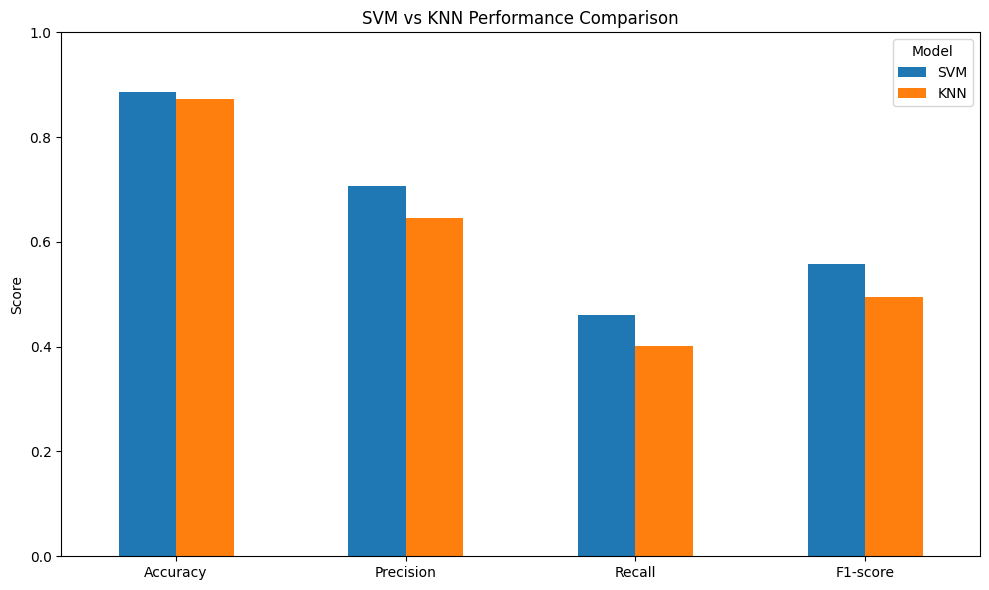

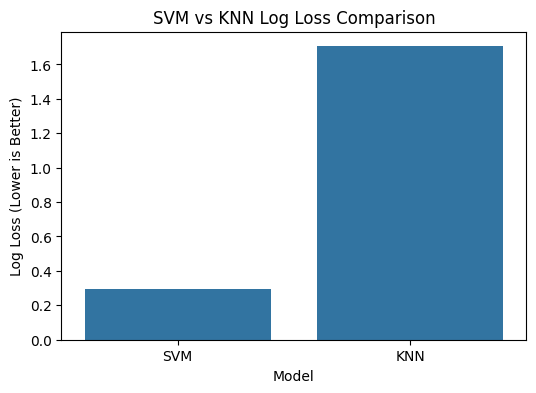

In [9]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

results.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("SVM vs KNN Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.barplot(data=results, x="Model", y="Log Loss")
plt.title("SVM vs KNN Log Loss Comparison")
plt.ylabel("Log Loss (Lower is Better)")
plt.show()


In [10]:

best_accuracy = results.loc[results["Accuracy"].idxmax(), "Model"]
best_f1 = results.loc[results["F1-score"].idxmax(), "Model"]
best_loss = results.loc[results["Log Loss"].idxmin(), "Model"]

print("COMPARATIVE ANALYSIS")
print("-------------------------------")
print("Highest accuracy:", best_accuracy)
print("Highest F1-score:", best_f1)
print("Lowest log loss:", best_loss)

print("\nModel Performance Summary:")
display(results.round(4))


COMPARATIVE ANALYSIS
-------------------------------
Highest accuracy: SVM
Highest F1-score: SVM
Lowest log loss: SVM

Model Performance Summary:


,Model,Accuracy,Precision,Recall,F1-score,Log Loss
0,SVM,0.8869,0.7068,0.4607,0.5578,0.2968
1,KNN,0.8731,0.6456,0.4005,0.4943,1.7046


## 7. Result

Support Vector Machine (SVM) and K-Nearest Neighbors (KNN) classification models were successfully implemented using the Online Shoppers Purchasing Intention Dataset.

The dataset contained 12,330 records and was divided into 80% training data (9,864 records) and 20% testing data (2,466 records).

Both models were evaluated using accuracy, precision, recall, F1-score, and log loss. Confusion matrices and comparative performance graphs were generated to visualize the results.

The SVM model achieved an accuracy of **88.69%**, while the KNN model achieved **87.31%**. The experimental results demonstrated that SVM performed better than KNN on the selected dataset.

## 8. Comparative Analysis

The performance of SVM and KNN was compared using five evaluation metrics to determine their effectiveness in predicting customer purchasing intentions.

### Performance Comparison Table

| Evaluation Metric | SVM | KNN |
|---|---|---|
| Accuracy | 88.69% | 87.31% |
| Precision | 70.68% | 64.56% |
| Recall | 46.07% | 40.05% |
| F1-score | 55.78% | 49.43% |
| Log Loss | 0.2968 | 1.7046 |

### Observations

1. **Accuracy:** SVM achieved higher accuracy (88.69%) compared to KNN (87.31%), indicating better overall classification performance.

2. **Precision:** SVM obtained 70.68% precision, whereas KNN achieved 64.56%, indicating that SVM was more reliable when predicting positive purchasing outcomes.

3. **Recall:** SVM achieved 46.07% recall compared to KNN's 40.05%, demonstrating better identification of actual purchasing customers.

4. **F1-score:** SVM achieved a higher F1-score (55.78%) than KNN (49.43%), indicating a better balance between precision and recall.

5. **Log Loss:** SVM recorded a lower log loss (0.2968) compared to KNN (1.7046), demonstrating better probabilistic prediction quality.

### Suitability of Classification Models

**Support Vector Machine (SVM):**

SVM is suitable for classification problems involving complex and nonlinear decision boundaries. It performs effectively on high-dimensional datasets when features are appropriately scaled. In this experiment, SVM achieved superior results across all evaluation metrics.

**K-Nearest Neighbors (KNN):**

KNN is a simple distance-based classification algorithm suitable for relatively small datasets. It requires minimal model training but can become computationally expensive during prediction. Its performance depends on feature scaling, distance metrics, and the selection of K.

### Final Comparative Findings

Based on the experimental results, **SVM outperformed KNN across all five evaluation metrics**.

SVM achieved the highest accuracy, precision, recall, and F1-score, along with the lowest log loss.

Therefore, SVM was identified as the more suitable classification model for predicting customer purchasing intentions on the selected dataset.

However, both models showed relatively low recall, suggesting that additional optimization could improve the identification of actual purchasing customers.

## 9. Conclusion

In this practical, Support Vector Machine (SVM) and K-Nearest Neighbors (KNN) classification algorithms were successfully implemented, trained, tested, and evaluated using the Online Shoppers Purchasing Intention Dataset.

The performance of both models was analyzed using accuracy, precision, recall, F1-score, log loss, confusion matrices, and comparative visualization graphs.

The experimental results showed that **SVM achieved better overall performance with 88.69% accuracy and 55.78% F1-score**, compared to KNN's 87.31% accuracy and 49.43% F1-score.

SVM also achieved a lower log loss, indicating better probabilistic prediction quality.

Thus, **SVM was found to be more suitable than KNN for the selected classification task**, based on the experimental results.

This practical provided hands-on experience in data preprocessing, classification model training, performance evaluation, and comparative analysis of machine learning algorithms.

.